# Entregable [N] – Clasificación Estelar con Árbol de Decisión

**Asignatura:** Machine Learning 1 
**Autora:** Taisiia Bogatyreva

## Objetivo
1. Clasificar objetos astronómicos (GALAXY, STAR, QSO) del conjunto *Stellar Classification Dataset – SDSS17* mediante un árbol de decisión.
2. Aplicar validación cruzada estratificada de 5 folds para evaluar la estabilidad del modelo.
3. Calcular las métricas de clasificación (accuracy, precision, recall, F1) y generar la matriz de confusión.
4. Documentar las decisiones tomadas y las conclusiones.

## Datos
- **Fuente:** [Kaggle – Stellar Classification Dataset (SDSS17)](https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17)
- **Variable objetivo:** `class`
- **Filas:** 100 000

## Metodología
La validación cruzada, las métricas y la matriz de confusión se calculan dentro de la función `analizar` (ver `src/evaluacion.py`).

### Funciones auxiliares

Las funciones `analizar` y `revisar_datos` **no están definidas en este notebook**: se importan del módulo [`common/evaluacion.py`](../common/evaluacion.py) del repositorio, para reutilizarlas en ambos análisis.

- `revisar_datos(df)`: revisión inicial del DataFrame (dimensiones, valores nulos, filas duplicadas, tipos de datos y estadísticas descriptivas).
- `analizar(X, y)`: ajusta el árbol de decisión y muestra, en este orden, (1) la búsqueda de parámetros con validación cruzada (`GridSearchCV`), (2) la accuracy por fold, (3) accuracy en entrenamiento vs. prueba, (4) el reporte de métricas por clase, (5) la matriz de confusión y (6) la importancia de las variables.

In [ ]:
import sys; sys.path.append("..")  # permite importar el módulo "common" de la raíz del repositorio
import pandas as pd
from common.evaluacion import analizar, revisar_datos # funciones definidas en common/evaluacion.py

In [ ]:
# Datos: Stellar Classification Dataset (SDSS17), Kaggle (fedesoriano).
# Archivo incluido en el repositorio: arbol-decision/data/star_classification.csv
df = pd.read_csv("data/star_classification.csv")

# revisar_datos (definida en common/evaluacion.py): nulos, duplicados, tipos y estadísticas
revisar_datos(df)
print("\nDistribución de clases:")
print(df["class"].value_counts())

Dimensiones: (100000, 18)
Total de valores nulos: 0
Filas completamente duplicadas: 0

--- Tipos de datos ---
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  str    
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD         

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
obj_ID,100000.0,NaN,NaN,NaN,1237664721814903296.0,8438559894562.569336,1237645942904389888.0,1237659161195119360.0,1237663463144292864.0,1237668350286447104.0,1237680531356386304.0
alpha,100000.0,NaN,NaN,NaN,177.629117,96.502241,0.005528,127.518222,180.9007,233.895005,359.99981
delta,100000.0,NaN,NaN,NaN,24.135305,19.644665,-18.785328,5.146771,23.645922,39.90155,83.000519
u,100000.0,NaN,NaN,NaN,21.980468,31.769291,-9999.0,20.352353,22.179135,23.68744,32.78139
g,100000.0,NaN,NaN,NaN,20.531387,31.750292,-9999.0,18.96523,21.099835,22.123767,31.60224
r,100000.0,NaN,NaN,NaN,19.645762,1.85476,9.82207,18.135828,20.12529,21.044785,29.57186
i,100000.0,NaN,NaN,NaN,19.084854,1.757895,9.469903,17.732285,19.405145,20.396495,32.14147
z,100000.0,NaN,NaN,NaN,18.66881,31.728152,-9999.0,17.460677,19.004595,19.92112,29.38374
run_ID,100000.0,NaN,NaN,NaN,4481.36606,1964.764593,109.0,3187.0,4188.0,5326.0,8162.0
rerun_ID,100000.0,NaN,NaN,NaN,301.0,0.0,301.0,301.0,301.0,301.0,301.0



Distribución de clases:
class
GALAXY    59445
STAR      21594
QSO       18961
Name: count, dtype: int64


In [3]:
# Valor atípico (-9999) en u, g, z
df = df[df["u"] > -1000]

# Columnas identificadoras, sin significado físico
cols_id = ["obj_ID", "run_ID", "rerun_ID", "cam_col", "field_ID",
           "spec_obj_ID", "plate", "MJD", "fiber_ID"]
X = df.drop(columns=cols_id + ["class"])
y = df["class"]
print(X.shape)

(99999, 8)


### Entrenamiento y evaluación del árbol de decisión

La siguiente celda llama a `analizar(X, y)` (código en `common/evaluacion.py`), que aplica la metodología descrita arriba: división 80 % / 20 %, búsqueda de parámetros con validación cruzada estratificada de 5 folds sobre el conjunto de entrenamiento, y evaluación del mejor modelo sobre el conjunto de prueba. Las variables `X` (predictoras) e `y` (objetivo `class`) se construyeron en la celda anterior.

Mejores parámetros: {'criterion': 'entropy', 'max_depth': 8}
Mejor accuracy en validación cruzada: 0.9736

--- Mejores 10 combinaciones evaluadas ---


,param_criterion,param_max_depth,mean_train_score,mean_test_score,std_test_score
27,log_loss,8,0.977790,0.973575,0.001184
17,entropy,8,0.977790,0.973575,0.001184
16,entropy,7,0.976153,0.973525,0.001374
26,log_loss,7,0.976153,0.973525,0.001374
28,log_loss,9,0.980131,0.973375,0.001527
18,entropy,9,0.980131,0.973375,0.001527
29,log_loss,10,0.982794,0.973312,0.000925
19,entropy,10,0.982794,0.973312,0.000925
8,gini,9,0.981387,0.973187,0.001674
6,gini,7,0.976181,0.972987,0.001752


Accuracy por fold: [0.973  0.9751 0.9726 0.9723 0.9749]
Media: 0.9736 ± 0.0012

Accuracy en entrenamiento: 0.9777
Accuracy en prueba:        0.9764

              precision    recall  f1-score   support

      GALAXY       0.97      0.99      0.98     11889
         QSO       0.96      0.92      0.94      3792
        STAR       1.00      1.00      1.00      4319

    accuracy                           0.98     20000
   macro avg       0.98      0.97      0.97     20000
weighted avg       0.98      0.98      0.98     20000



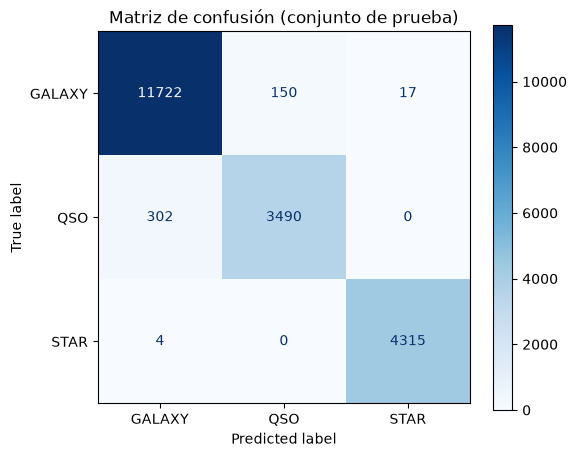

Top 10 variables más importantes:
redshift    0.9118
g           0.0516
u           0.0149
z           0.0124
i           0.0056
r           0.0021
alpha       0.0009
delta       0.0009
dtype: float64


In [ ]:
# analizar() devuelve el mejor árbol encontrado; el resto de resultados
# (parámetros, validación cruzada, métricas, matriz de confusión) se imprime/grafica dentro de la función.

modelo_star = analizar(X, y, guardar_matriz="../reports/figures/matriz_stellar.png") # en Credit Score: modelo_credit = analizar(X, y)


## Conclusiones

**Método.** División 80 % / 20 % estratificada y búsqueda en rejilla (`GridSearchCV`) sobre el conjunto de entrenamiento, con validación cruzada estratificada de 5 folds. Se probaron `criterion` (gini, entropy, log_loss) y `max_depth` (None, 2 a 10).

**Resultados.** Mejores parámetros: `criterion='entropy'`, `max_depth=8`.

| Métrica | Valor |
|---|---|
| Accuracy media en validación cruzada | 0.9736 ± 0.0012 |
| Accuracy en entrenamiento | 0.9777 |
| Accuracy en prueba | 0.9764 |

| Clase | Precision | Recall | F1 |
|---|---|---|---|
| GALAXY | 0.97 | 0.99 | 0.98 |
| QSO | 0.96 | 0.92 | 0.94 |
| STAR | 1.00 | 1.00 | 1.00 |

1. **Sin sobreajuste.** La accuracy de entrenamiento (0.9777) y la de prueba (0.9764) casi coinciden, y los 5 folds varían muy poco (0.9723–0.9751).
2. **Mejora frente a la línea base.** Responder siempre "GALAXY" daría ≈ 59 %; el modelo alcanza ≈ 97.6 %.
3. **Parámetros.** `entropy` y `log_loss` dan resultados idénticos. Las profundidades 7 a 10 tienen una accuracy de validación casi igual (0.9733–0.9736), con diferencias menores que la desviación entre folds. Al aumentar la profundidad, la accuracy de entrenamiento sube (0.9762 → 0.9828) y la de validación no: el árbol empieza a memorizar.
4. **Errores.** De 473 errores en prueba, 452 (≈ 96 %) son confusiones entre GALAXY y QSO (302 quasares clasificados como galaxia y 150 galaxias como quasar). STAR casi no se confunde.
5. **Variables importantes.** `redshift` concentra el 91.2 % de la importancia, seguida de `g` (5.2 %), `u` (1.5 %) y `z` (1.2 %). `alpha` y `delta` aportan menos de 0.1 % cada una.

## Выводы

**Метод.** Разделение данных 80 % / 20 % со стратификацией и перебор параметров (`GridSearchCV`) на обучающей выборке с 5-фолдовой стратифицированной кросс-валидацией. Перебирались `criterion` (gini, entropy, log_loss) и `max_depth` (None, 2–10).

**Результаты.** Лучшие параметры: `criterion='entropy'`, `max_depth=8`.

| Метрика | Значение |
|---|---|
| Средняя accuracy на кросс-валидации | 0.9736 ± 0.0012 |
| Accuracy на обучающей выборке | 0.9777 |
| Accuracy на тестовой выборке | 0.9764 |

| Класс | Precision | Recall | F1 |
|---|---|---|---|
| GALAXY | 0.97 | 0.99 | 0.98 |
| QSO | 0.96 | 0.92 | 0.94 |
| STAR | 1.00 | 1.00 | 1.00 |

1. **Переобучения нет.** Accuracy на обучении (0.9777) почти совпадает с accuracy на тесте (0.9764), а пять фолдов различаются слабо (0.9723–0.9751).
2. **Улучшение относительно базового уровня.** Если всегда отвечать «GALAXY», accuracy будет ≈ 59 %. Модель даёт ≈ 97.6 %.
3. **Параметры.** `entropy` и `log_loss` дают одинаковые результаты. Глубины 7–10 почти не различаются по качеству на валидации (0.9733–0.9736), а разница меньше разброса между фолдами. С ростом глубины accuracy на обучении растёт (0.9762 → 0.9828), а на валидации нет: дерево начинает запоминать данные.
4. **Ошибки.** Из 473 ошибок на тесте 452 (≈ 96 %) приходятся